# 0. Vérification de l'environnement

Avant de commencer, on vérifie que l'environnement Python du projet (`supportbot`) est bien
utilisé par le notebook, que PyTorch est installé, et qu'une couche LSTM fonctionne.
Le développement se fait sur CPU ; l'entraînement complet sera réalisé sur GPU (Kaggle).

In [1]:
import sys
import torch
import torch.nn as nn

print("Python utilisé :", sys.executable)
print("Version de PyTorch :", torch.__version__)
print("GPU NVIDIA disponible :", torch.cuda.is_available())

# On crée un petit LSTM, comme celui du projet
lstm = nn.LSTM(input_size=8, hidden_size=16, batch_first=True)

# Un faux batch : 2 phrases, de 5 mots, chaque mot = vecteur de 8 nombres
x = torch.randn(2, 5, 8)
sortie, (h, c) = lstm(x)

print("Forme de la sortie :", sortie.shape)  # attendu : (2, 5, 16)
print("✅ Tout fonctionne !")

Python utilisé : c:\Users\ranim\anaconda3\envs\supportbot\python.exe
Version de PyTorch : 2.14.1+cpu
GPU NVIDIA disponible : False
Forme de la sortie : torch.Size([2, 5, 16])
✅ Tout fonctionne !


# 1. Chargement et exploration du dataset

**Source :** *Customer Support on Twitter*, publié par Thought Vector sur Kaggle.

Ce dataset contient des tweets échangés entre des **clients** et les **services clients**
de grandes marques (Apple, Amazon, Spotify…). Chaque tweet indique s'il a été écrit par
un client ou par une entreprise, et à quel tweet il répond.

**Objectif de cette section :** comprendre la structure des données avant de construire
les paires *message client → réponse de l'agent*.

In [2]:
import pandas as pd
import numpy as np

# Afficher le texte complet des tweets (sinon pandas coupe les longs textes)
pd.set_option("display.max_colwidth", 150)

# Chemin RELATIF : le notebook est dans "notebooks/", on remonte d'un niveau avec ".."
# (un chemin relatif fonctionne sur n'importe quel ordinateur, sur Kaggle et sur GitHub)
CHEMIN_DATA = "../data/raw/twcs.csv"

df = pd.read_csv(CHEMIN_DATA)

print(f"Nombre de tweets   : {len(df):,}")
print(f"Nombre de colonnes : {df.shape[1]}")
print(f"Colonnes           : {list(df.columns)}")
df.head(3)

Nombre de tweets   : 2,811,774
Nombre de colonnes : 7
Colonnes           : ['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id']


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist you. We would need to get you into a private secured link to further assist.,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messages and no one is responding as usual,1,4.0


# 2. Contrôle qualité des données

La qualité d'un jeu de données n'est pas absolue : elle s'évalue **par rapport à son usage**.
Notre usage : entraîner un modèle séquence-à-séquence qui génère la **réponse d'un agent**
à partir du **message d'un client**, en anglais.

Nos exigences de qualité sont donc :
- les paires *client → agent* doivent être **correctes** (bonne réponse au bon message) ;
- les textes doivent être **exploitables** (non vides, en anglais) ;
- les réponses ne doivent pas être **dominées par des réponses types**, sinon le modèle
  apprendra à toujours répondre la même chose.

Les contraintes ci-dessous sont des **hypothèses** sur les données : une violation signale
une **incohérence**, pas forcément une erreur. Chaque violation est analysée avant
toute décision de réparation.

Pour garder une trace de chaque transformation, on tient un **journal de provenance**
(étape, opérateur, nombre de lignes avant et après, justification).


In [3]:
journal = []

def enregistrer_etape(etape, operateur, n_entree, n_sortie, justification):
    """Ajoute une ligne au journal de provenance du pipeline."""
    journal.append({
        "étape": etape,
        "opérateur": operateur,
        "lignes en entrée": n_entree,
        "lignes en sortie": n_sortie,
        "lignes retirées": n_entree - n_sortie,
        "justification": justification,
    })

enregistrer_etape("Chargement de twcs.csv", "lecture", len(df), len(df),
                  "Données brutes Kaggle (Thought Vector), aucune modification")
pd.DataFrame(journal)

,étape,opérateur,lignes en entrée,lignes en sortie,lignes retirées,justification
0,Chargement de twcs.csv,lecture,2811774,2811774,0,"Données brutes Kaggle (Thought Vector), aucune modification"


## 2.1 Complétude

**Complétude des colonnes.** Les colonnes essentielles (tweet_id, author_id, inbound,
created_at, text) sont complètes. Seules les deux colonnes de liens ont des valeurs manquantes.

**Diagnostic du mécanisme.** Avant de décider quoi faire d'une valeur manquante, il faut
comprendre **pourquoi** elle manque (MCAR, MAR, MNAR).
Ici, une valeur manquante n'est pas une information perdue : c'est une valeur
**non applicable**. Un premier message n'a pas de parent, et un dernier message
n'a pas de réponse. On vérifie si ce manque dépend d'une variable observée (`inbound`).

In [4]:
print("=== Types des colonnes ===")
print(df.dtypes)

print("\n=== Valeurs manquantes par colonne ===")
missing = pd.DataFrame({
    'colonne': df.columns,
    'nb_manquantes': df.isnull().sum().values,
    'pourcentage (%)': (df.isnull().mean() * 100).round(2).values
})
missing = missing.sort_values('pourcentage (%)', ascending=False).reset_index(drop=True)
missing

=== Types des colonnes ===
tweet_id                     int64
author_id                      str
inbound                       bool
created_at                     str
text                           str
response_tweet_id              str
in_response_to_tweet_id    float64
dtype: object

=== Valeurs manquantes par colonne ===


,colonne,nb_manquantes,pourcentage (%)
0,response_tweet_id,1040629,37.01
1,in_response_to_tweet_id,794335,28.25
2,tweet_id,0,0.00
3,inbound,0,0.00
4,author_id,0,0.00
5,text,0,0.00
6,created_at,0,0.00


### 2.1.1 Diagnostic du mécanisme des valeurs manquantes

Avant toute décision, on cherche **pourquoi** les valeurs manquent (MCAR, MAR ou MNAR).
Méthode : on crée un indicateur « valeur manquante » et on compare son taux selon
des variables observées (rôle de l'auteur, date, longueur du texte).
Si le taux varie fortement, le manque n'est pas complètement aléatoire (pas MCAR).

### Le manque dépend-il du rôle (client ou entreprise) ?

In [5]:
indicateurs = pd.DataFrame({
    "sans parent (in_response_to vide)": df["in_response_to_tweet_id"].isna(),
    "sans réponse (response_tweet_id vide)": df["response_tweet_id"].isna(),
})
indicateurs["rôle"] = df["inbound"].map({True: "Client", False: "Entreprise"})

print("=== % de valeurs manquantes selon le rôle de l'auteur ===")
(indicateurs.groupby("rôle").mean() * 100).round(2)

=== % de valeurs manquantes selon le rôle de l'auteur ===


,sans parent (in_response_to vide),sans réponse (response_tweet_id vide)
rôle,,
Client,51.20,15.22
Entreprise,0.55,63.32


Le taux de valeurs manquantes varie fortement selon le rôle de l’auteur : 51,2 % des tweets clients n’ont pas de tweet parent, contre 0,55 % des tweets d’entreprise ; à l’inverse, 63,3 % des tweets d’entreprise n’ont pas de réponse, contre 15,2 % des tweets clients. Le manque dépend donc d’une variable observée : il n’est pas MCAR mais compatible avec MAR. Ces valeurs correspondent majoritairement à des valeurs non applicables (début et fin de conversation) et ne sont donc pas imputées.

### Le manque dépend-il de la date ?

In [6]:
df["date"] = pd.to_datetime(df["created_at"], format="%a %b %d %H:%M:%S %z %Y", errors="coerce")
df["mois"] = df["date"].dt.strftime("%Y-%m")

print("=== % de tweets sans réponse, par mois ===")
df.groupby("mois")["response_tweet_id"].agg(
    nb_tweets="size",
    pct_sans_reponse=lambda s: round(s.isna().mean() * 100, 2),
)

=== % de tweets sans réponse, par mois ===


,nb_tweets,pct_sans_reponse
mois,,
2008-05,2,0.00
2010-02,1,0.00
2010-03,2,0.00
2010-07,2,0.00
2010-08,1,0.00
...,...,...
2017-08,2100,3.57
2017-09,13168,11.38
2017-10,1252954,37.47


Bien que les dates s’étendent de 2008 à 2017, environ 99 % des tweets ont été publiés entre octobre et début décembre 2017. Les rares tweets plus anciens sont des messages auxquels un utilisateur a répondu pendant la période de collecte : ils reflètent la méthode de collecte, basée sur les conversations, et non des erreurs. Le taux de tweets sans réponse augmente légèrement en décembre, ce qui suggère un effet de fin de collecte: le manque dépend faiblement de la date, ce qui est compatible avec un mécanisme MAR.

### Le manque dépend-il de la longueur du texte ?

In [7]:
df["longueur"] = df["text"].str.len()

print("=== Longueur des textes : tweets AVEC parent (False) vs SANS parent (True) ===")
df.groupby(df["in_response_to_tweet_id"].isna())["longueur"].describe().round(1)

=== Longueur des textes : tweets AVEC parent (False) vs SANS parent (True) ===


,count,mean,std,min,25%,50%,75%,max
in_response_to_tweet_id,,,,,,,,
False,2017439.0,111.6,52.4,1.0,75.0,113.0,139.0,513.0
True,794335.0,119.8,51.8,1.0,84.0,120.0,140.0,328.0


**Interprétation.** Les tweets sans parent (débuts de conversation) sont légèrement plus longs
(médiane de 120 caractères contre 113) : c'est cohérent avec un premier message dans lequel le
client expose son problème. L'écart reste modeste et doit être interprété avec prudence, car les
deux groupes n'ont pas la même composition : les tweets sans parent sont presque tous des
clients, alors que les tweets avec parent mélangent clients et agents (variable de confusion).

Le maximum (513 caractères) dépasse la limite de 280 caractères d'un tweet : cela s'explique
probablement par les mentions en début de réponse (non comptées par Twitter) et par les
caractères codés en HTML (`&amp;`, `&gt;`). Ce point est vérifié en section 2.3.

### Interprétation : 

Les valeurs manquantes ne concernent que les deux colonnes de liens. Leur taux dépend fortement du rôle de l’auteur (client ou entreprise), et plus faiblement de la date : le manque n’est donc pas MCAR, mais compatible avec un mécanisme MAR. Dans la grande majorité des cas, ces valeurs sont non applicables : un tweet sans parent est un début de conversation (surtout chez les clients), un tweet sans réponse est une fin de conversation (surtout chez les entreprises). Une faible part correspond à de véritables manques, liés à la fin de la période de collecte. Aucune imputation n’est appliquée, car inventer un lien créerait de fausses conversations.

--> ***Les valeurs manquantes ne sont ni supprimées ni imputées. La suppression des lignes incomplètes éliminerait tous les débuts et fins de conversation, c’est-à-dire la majorité des messages utiles ; l’imputation créerait de faux liens entre tweets. Les valeurs manquantes sont donc conservées, car elles portent une information sur la structure des conversations. Elles sont gérées lors de la construction des paires : seuls les liens effectivement observés entre un message client et une réponse d’agent sont utilisés.***

### Regarder des exemples suspects (On isole le cas inattendu : un tweet d’entreprise qui ne répond à personne)

In [8]:
entreprises_sans_parent = df[(~df["inbound"]) & df["in_response_to_tweet_id"].isna()]
print(f"Tweets d'entreprise sans parent : {len(entreprises_sans_parent):,}")

entreprises_sans_parent[["author_id", "text"]].sample(
    min(10, len(entreprises_sans_parent)), random_state=42
)

Tweets d'entreprise sans parent : 6,989


,author_id,text
2509370,British_Airways,@146059 is back in action to celebrate an incredible £17 million raised for #BAFlyingStart and @117823. A big thank you to all those involved! htt...
1044437,AmazonHelp,@391979 You may choose &gt;&gt;Prime or something else&gt;&gt;Placing an order&gt;&gt;Product information and can contact our support team. ^NK
2483673,TMobileHelp,"@362519 Thank you for staying engaged with us in DM, Qiao. *JennaLundh"
2225931,SW_Help,#DisruptionSWR **NEW** Due to cattle on the railway between Totton and Brockenhurst trains have to run at reduced speed on all lines. Delays up to...
1698416,XboxSupport,"@554254 Hi there, what happens when you try? Any specific error message? If you try a 1 ^ZM"
56569,SW_Help,"*NEW* Due to congestion caused by earlier incidents on the network, trains have to travel at reduced speed. Delays of up to 10 minutes are expecte..."
507627,nationalrailenq,#WatfordJunction- Trains that do run are expected to be busier than normal so travel should be considered for later in the day or on Monday where ...
1590530,marksandspencer,.@127894 @525823 Slightly comfier up here 😜 #uokhun #lovethebear https://t.co/5Wn5YeODDf
865494,nationalrailenq,"#StormBrian to affect Southern, Gatwick Express and Thameslink services until Monday 23 October. More info: https://t.co/v5q8kB54BY"
1225077,hulu_support,We are currently investigating reports of users having trouble streaming content from their Watchlist on living room devices.


Les 6 989 tweets d’entreprise sans parent (0,55 %) relèvent de deux situations : des messages spontanés (annonces de perturbations, pannes, communication marketing), pour lesquels le lien est non applicable, et des réponses adressées à un client dont le message d’origine n’a pas été collecté, qui traduisent un défaut de complétude de la population. Dans les deux cas, aucun message client ne peut leur être associé : ces tweets sont exclus lors de la construction des paires.

## 2.2 Unicité

On distingue :
- les **doublons exacts** : la même ligne ou le même identifiant enregistré plusieurs fois ;
- les **quasi-doublons** : des textes qui ne diffèrent que par des détails (mention, lien,
  signature de l'agent, numéro). Pour les révéler, on applique d'abord une étape de
  **standardisation** des textes avant de les comparer, comme dans les méthodes classiques
  de détection de doublons.

Pour un chatbot, les quasi-doublons parmi les réponses d'agents sont les **réponses types**
(« Please DM us… ») : s'ils dominent les données, le modèle risque de toujours les générer.

### Doublons exacts

**Pourquoi vérifier que `tweet_id` est unique ?** Toute la construction des paires repose sur
les identifiants : on relie chaque réponse à son message d'origine grâce à
`in_response_to_tweet_id`. Si un même identifiant désignait deux tweets différents, on ne
saurait pas lequel est le bon parent et on risquerait de créer de fausses paires.

In [9]:
nb_lignes_dupliquees = df.duplicated().sum()
nb_id_dupliques = df["tweet_id"].duplicated().sum()
nb_textes_dupliques = df["text"].duplicated().sum()

print(f"Lignes entièrement dupliquées : {nb_lignes_dupliquees:,}")
print(f"tweet_id en double            : {nb_id_dupliques:,}")
print(f"Textes exactement identiques  : {nb_textes_dupliques:,}")

Lignes entièrement dupliquées : 0
tweet_id en double            : 0
Textes exactement identiques  : 29,156


**Interprétation.** Aucune ligne et aucun `tweet_id` ne sont dupliqués : `tweet_id` est une
**clé** (dépendance fonctionnelle `tweet_id → toutes les colonnes`), ce qui garantit que les liens
entre tweets sont sans ambiguïté. Les 29 156 textes strictement identiques (≈ 1 %) sont peu
nombreux, car presque chaque tweet commence par une mention différente (`@115712`, `@391979`…)
qui masque les répétitions. D'où l'étape suivante.

### Quasi-doublons (réponses types)

**Pourquoi standardiser avant de chercher des doublons ?** Deux réponses d'agents peuvent avoir
exactement le même contenu tout en paraissant différentes, à cause de détails qui changent à
chaque fois :

| Réponse brute | Ce qui change |
|---|---|
| `@115712 Send us a DM with your email ^JK` | mention, signature |
| `@391979 send us a DM with your email -AB` | mention, majuscule, signature |

Une comparaison directe les considère comme **différentes**. La standardisation supprime ces
détails sans importance pour le sens (majuscules, apostrophes typographiques, liens, mentions,
signatures, nombres) afin que deux textes **équivalents** deviennent **identiques**. On peut
alors mesurer la vraie proportion de réponses répétées.

*Remarque 1 : cette standardisation sert uniquement à **détecter** les répétitions. Le texte
utilisé pour entraîner le modèle sera nettoyé séparément lors du prétraitement.*

*Remarque 2 : Pour la standardisation, on a utilisé des expressions régulières (module `re`) pour supprimer les liens, les mentions, les signatures et les nombres, puis on a mis le texte en minuscules.*

In [10]:
import re

def standardiser(texte):
    """Standardise un tweet pour révéler les quasi-doublons (réponses types)."""
    texte = str(texte).lower()
    texte = texte.replace("’", "'")                              # apostrophe courbe -> droite
    texte = re.sub(r"https?://\S+", " ", texte)                  # liens
    texte = re.sub(r"@\w+", " ", texte)                          # mentions
    texte = re.sub(r"\s[\^\-\*]\s?[a-z]{1,20}\s*$", " ", texte)  # signature d'agent (^jk, -ab, *jennalundh)
    texte = re.sub(r"\d+", " ", texte)                           # nombres
    texte = re.sub(r"\s+", " ", texte).strip()                   # espaces multiples
    return texte

entreprises = df[~df["inbound"]].copy()
entreprises["texte_standard"] = entreprises["text"].map(standardiser)

nb_exact = entreprises["text"].duplicated(keep=False).sum()
nb_quasi = entreprises["texte_standard"].duplicated(keep=False).sum()
nb_vides_standard = (entreprises["texte_standard"] == "").sum()

print(f"Réponses d'entreprise                          : {len(entreprises):,}")
print(f"... identiques à une autre (texte brut)        : {nb_exact:,} ({nb_exact/len(entreprises):.1%})")
print(f"... identiques à une autre (texte standardisé) : {nb_quasi:,} ({nb_quasi/len(entreprises):.1%})")
print(f"... vides après standardisation                : {nb_vides_standard:,}")
print("\n=== Les 15 réponses types les plus fréquentes ===")
entreprises["texte_standard"].value_counts().head(15)

Réponses d'entreprise                          : 1,273,931
... identiques à une autre (texte brut)        : 5,261 (0.4%)
... identiques à une autre (texte standardisé) : 270,601 (21.2%)
... vides après standardisation                : 1,606

=== Les 15 réponses types les plus fréquentes ===


texte_standard
here's what you can do to work around the issue until it's fixed in a future software update:                           6258
here to help. send us a note at so our team can connect.                                                                1860
                                                                                                                        1606
we're awaiting for your response to resolve ur issue. pls provide the same within next hrs. rgds, idea care             1533
we offer support via twitter in english. contact us for help in your preferred language here:                           1100
to be immediately connected with our critical response line, click the "call me" button and enter your number at        1000
we offer support via twitter in english. get help in spanish here: or join                                               798
thanks for reaching out. we have a workaround for this here: dm us if you still need help.                    

**Interprétation.** Avant standardisation, 0,4 % des réponses d'entreprise sont identiques à une
autre ; après standardisation, cette proportion passe à environ 21 % : **une réponse d'agent sur
cinq est une réponse type**. Sans standardisation, ces répétitions seraient restées invisibles.

Les réponses types les plus fréquentes sont des redirections vers un message privé
(« send us a dm… »), un contournement de bug logiciel répété plusieurs milliers de fois et lié à
un incident précis de la période, des redirections vers une autre langue, et des formules de
clôture (« you're welcome. »). Environ 1 600 réponses sont **vides** après standardisation : elles
ne contenaient qu'une mention, un lien ou des nombres.

**Risque pour le modèle :** le modèle apprend surtout ce qu’il voit souvent. Si une même réponse apparaît des milliers de fois, il risque de la donner à n’importe quel message.

**Décision :** on ne garde pas toutes ces réponses (le chatbot deviendrait répétitif), mais on ne les supprime pas non plus (elles sont utiles et correspondent à la façon réelle de répondre des agents). Leur nombre d'occurrences sera donc **plafonné** lors de la construction des paires (on limite donc le nombre d’exemples pour chaque réponse type, par exemple à 100 au maximum) et les réponses **vides après standardisation** seront **exclues** (les réponses sans aucun mot (seulement un lien ou une mention) sont supprimées, car elles n’apprennent rien au modèle).

*Remarque : Les répétitions sont surtout problématiques en sortie, car le modèle apprend à générer les réponses les plus fréquentes. Les messages des clients ne sont que lus par le modèle, et ils sont rédigés librement par chaque client, donc beaucoup moins répétitifs que les réponses types des agents.*
 

## 2.3 Exactitude syntaxique et adéquation à l'usage

Une valeur est **syntaxiquement exacte** si elle appartient à son **domaine** de valeurs
admissibles (contrainte de domaine) : une date lisible et plausible, un identifiant bien formé,
un texte non vide.

On vérifie aussi l'**adéquation à l'usage** : notre modèle apprend l'anglais, donc les tweets écrits dans une autre langue » (on détecte aussi l’espagnol, le français…) sont hors périmètre.


### Les dates

On vérifie que chaque date est lisible et plausible (entre la création de Twitter en 2006
et la publication du dataset fin 2017).

In [11]:
debut_twitter = pd.Timestamp("2006-03-21", tz="UTC")   # premier tweet de l'histoire
publication = pd.Timestamp("2018-01-01", tz="UTC")     # le dataset a été publié fin 2017

nb_dates_invalides = df["date"].isna().sum()
nb_dates_hors_periode = ((df["date"] < debut_twitter) | (df["date"] > publication)).sum()
part_periode = df["mois"].isin(["2017-10", "2017-11", "2017-12"]).mean()

print(f"Dates illisibles (hors domaine)           : {nb_dates_invalides:,}")
print(f"Dates hors période plausible (2006-2017)  : {nb_dates_hors_periode:,}")
print(f"Période couverte : du {df['date'].min()} au {df['date'].max()}")
print(f"Part des tweets d'octobre à décembre 2017 : {part_periode:.2%}")

Dates illisibles (hors domaine)           : 0
Dates hors période plausible (2006-2017)  : 0
Période couverte : du 2008-05-08 20:13:59+00:00 au 2017-12-03 23:14:01+00:00
Part des tweets d'octobre à décembre 2017 : 99.26%


**Interprétation :** 

Toutes les dates sont lisibles et comprises dans la période plausible :
la colonne `created_at` est syntaxiquement exacte, aucune réparation n'est nécessaire.
Les dates vont du 8 mai 2008 au 3 décembre 2017, mais 99,26 % des tweets ont été publiés
entre octobre et début décembre 2017 : la collecte couvre en réalité environ deux mois et
s'arrête le 3 décembre 2017. 

### Les identifiants 


Lors de l'affichage des types (section 2.1), on a vu que `tweet_id` est de type `int64`
(entier) et `in_response_to_tweet_id` de type `float64` (nombre à virgule) : pandas a donc
réussi à lire toutes leurs valeurs comme des nombres, ce qui garantit déjà leur format.
On vérifie seulement que ces identifiants sont des **entiers positifs**, comme doit l'être
un identifiant de tweet.

In [12]:
# tweet_id (int64) : entier garanti par le type, on vérifie qu'il est positif
nb_id_invalides = (df["tweet_id"] <= 0).sum()

# in_response_to_tweet_id (float64) : on vérifie qu'il est entier ET positif
parents = df["in_response_to_tweet_id"].dropna()
nb_parents_non_entiers = (parents % 1 != 0).sum()
nb_parents_negatifs = (parents <= 0).sum()

print(f"tweet_id nuls ou négatifs                  : {nb_id_invalides:,}")
print(f"in_response_to_tweet_id non entiers        : {nb_parents_non_entiers:,}")
print(f"in_response_to_tweet_id nuls ou négatifs   : {nb_parents_negatifs:,}")

tweet_id nuls ou négatifs                  : 0
in_response_to_tweet_id non entiers        : 0
in_response_to_tweet_id nuls ou négatifs   : 0


Tous les identifiants sont des entiers positifs : ils sont valides et peuvent être utilisés pour relier les tweets entre eux.

### `response_tweet_id` et les textes

**`response_tweet_id`** est stockée en texte, car certaines cases contiennent plusieurs
identifiants séparés par des virgules (par exemple `5,7`). On vérifie avec une expression
régulière que chaque valeur a bien la forme attendue : un ou plusieurs nombres séparés par
des virgules. On compte aussi les tweets qui ont reçu plusieurs réponses.

**Les textes** : on vérifie qu'aucun tweet n'est vide, et on repère :
- les textes très courts (moins de 5 caractères), peu utiles pour l'apprentissage ;
- les textes de plus de 280 caractères, la limite d'un tweet en 2017 ;
- les textes contenant des caractères codés en HTML (`&amp;`, `&gt;`…), qu'il faudra décoder
  lors du nettoyage.

In [13]:
# Format attendu de response_tweet_id : un ou plusieurs nombres séparés par des virgules ("5" ou "5,6")
reponses_non_vides = df["response_tweet_id"].dropna().astype(str)
nb_format_invalide = (~reponses_non_vides.str.fullmatch(r"\d+(,\d+)*")).sum()
nb_reponses_multiples = reponses_non_vides.str.contains(",").sum()
print(f"response_tweet_id hors format      : {nb_format_invalide:,}")
print(f"Tweets ayant plusieurs réponses    : {nb_reponses_multiples:,}")

nb_textes_vides = (df["text"].str.strip() == "").sum()
nb_textes_courts = (df["longueur"] < 5).sum()
nb_textes_longs = (df["longueur"] > 280).sum()
nb_html = df["text"].str.contains(r"&(?:amp|gt|lt|quot);", regex=True).sum()
print(f"\nTextes vides                       : {nb_textes_vides:,}")
print(f"Textes très courts (< 5 caractères) : {nb_textes_courts:,}")
print(f"Textes de plus de 280 caractères    : {nb_textes_longs:,}")
print(f"Textes avec caractères codés (HTML) : {nb_html:,}")

print("\n=== Exemples de textes de plus de 280 caractères ===")
for t in df.loc[df["longueur"] > 280, "text"].head(3):
    print("-", t)

response_tweet_id hors format      : 0
Tweets ayant plusieurs réponses    : 222,426

Textes vides                       : 0
Textes très courts (< 5 caractères) : 53
Textes de plus de 280 caractères    : 22,618
Textes avec caractères codés (HTML) : 97,802

=== Exemples de textes de plus de 280 caractères ===
- @marksandspencer ou must charge at least 5p a bag (including VAT) for carrier bags that are all of the following:

unused - it’s new and hasn’t already been used for sold goods to be taken away or delivered
plastic and 70 microns thick or less
it has handles, an opening and isn’t sealed
- @marksandspencer aren’t require charge 4 a bag:
paper bags
shops in airports, or on board trains, aeroplanes or ships
bags which only contain certain items, such as unwrapped food, raw meat and fish where there is a food safety risk, prescription medicines, uncovered blades, seeds, bulbs &amp; 🌷s
- @115771 Hi, you can change your Microsoft account email through the steps here: https://t.co/DkEhOH

**Interprétation :** 

Toutes les valeurs de `response_tweet_id` respectent le format attendu.
222 426 tweets (≈ 12,6 % des tweets ayant une réponse) ont reçu plusieurs réponses : un même
message client peut donc donner plusieurs paires, ce qui sera traité lors de la construction
des paires.

Aucun texte n'est vide et les textes très courts (53) sont négligeables. Les 22 618 textes de
plus de 280 caractères ne sont pas des erreurs : Twitter ne compte pas les mentions en début de
réponse, compte chaque lien pour 23 caractères et chaque caractère codé (`&amp;`) pour un seul ;
ces textes seront raccourcis lors du prétraitement (troncature). Enfin, 97 802 textes (≈ 3,5 %)
contiennent des caractères codés en HTML et des retours à la ligne : ils seront décodés et
normalisés lors du nettoyage.

### Adéquation à l'usage : la langue

Deux méthodes complémentaires sont combinées pour exclure les tweets non anglais : 
1) la détection des alphabets non latins, très fiable mais limitée aux langues qui n’utilisent pas l’alphabet latin (japonais notamment)
2) le comptage de mots-outils (stopwords), qui repère l’espagnol, le français etc.. mais reste approximatif sur les textes très courts.

In [14]:
# Plages de caractères : cyrillique, arabe, thaï, japonais, chinois, coréen
ecritures_non_latines = r"[\u0400-\u04FF\u0600-\u06FF\u0E00-\u0E7F\u3040-\u30FF\u4E00-\u9FFF\uAC00-\uD7AF]"
masque_non_latin = df["text"].str.contains(ecritures_non_latines, regex=True)
nb_non_latin = masque_non_latin.sum()

print(f"Tweets contenant un alphabet non latin : {nb_non_latin:,} ({nb_non_latin/len(df):.2%})")
print("\n=== Marques concernées (réponses d'entreprise) ===")
print(df.loc[masque_non_latin & ~df["inbound"], "author_id"].value_counts().head(5))
df.loc[masque_non_latin, ["author_id", "text"]].head(5)

Tweets contenant un alphabet non latin : 22,675 (0.81%)

=== Marques concernées (réponses d'entreprise) ===
author_id
AmazonHelp        9919
NortonSupport      554
AirAsiaSupport      20
AskPayPal           20
AirbnbHelp           9
Name: count, dtype: int64


,author_id,text
181,AmazonHelp,@115770 こんにちは、アマゾン公式です。Fire TV Stickが見れないというのは、どのような状況でしょうか。一般的なトラブルシューティングを記載したヘルプがございますので、ご参照ください。https://t.co/2pbG55qJ7h ET
182,115770,@AmazonHelp ありがとうございます。\n今、電話で主人が対応していただいてます。
183,115770,@AmazonHelp 電話で対応してもらいましたが改良されませんでした。\n保証期間も過ぎてるので買い直しになるんでしょうね。
184,AmazonHelp,@115770 カスタマーサービスにてお問い合わせ済みとのことで、お手数をおかけいたしました。リプライいただきありがとうございました。ET
185,115770,@AmazonHelp こちらこそありがとうございました。


In [15]:
mots_en = {"the", "and", "is", "to", "you", "i", "of", "for", "in", "it", "my", "we",
           "your", "this", "that", "on", "with", "can", "please", "are", "have"}

mots_outils = {
    "espagnol":  {"el", "los", "las", "que", "y", "en", "una", "por", "para", "con", "es", "hola",
                  "gracias", "está", "pero", "muy", "su", "nos", "tu", "usted"},
    "français":  {"le", "les", "des", "et", "est", "une", "pour", "pas", "que", "bonjour", "merci",
                  "vous", "nous", "je", "avec", "sur", "ce", "votre", "mon", "bien"},
    "allemand":  {"der", "das", "und", "ist", "nicht", "ich", "sie", "wir", "mit", "für", "auf",
                  "ein", "eine", "danke", "bitte", "hallo", "sind", "haben", "zu", "ihr"},
    "portugais": {"não", "obrigado", "obrigada", "você", "olá", "está", "muito", "seu", "sua",
                  "os", "que", "em", "da", "uma", "com", "para", "mas"},
    "italien":   {"il", "che", "non", "per", "grazie", "ciao", "sono", "una", "della", "con",
                  "questo", "anche", "ma", "ho", "del"},
}

def langue_probable(texte):
    """Estime la langue d'un tweet en comptant les mots-outils de chaque langue."""
    mots = re.findall(r"[a-záéíóúñàâçèêëîïôûüäößãõìò']+", str(texte).lower())
    n_en = sum(m in mots_en for m in mots)
    scores = {langue: sum(m in liste for m in mots) for langue, liste in mots_outils.items()}
    meilleure = max(scores, key=scores.get)
    if scores[meilleure] >= 2 and scores[meilleure] > n_en:
        return meilleure
    return "anglais (ou indéterminé)"

df["langue"] = df["text"].map(langue_probable)

print("=== Langue probable des tweets ===")
print(df["langue"].value_counts())
print("\n=== Marques concernées (réponses d'entreprise non anglaises) ===")
print(df.loc[(df["langue"] != "anglais (ou indéterminé)") & ~df["inbound"], "author_id"].value_counts().head(5))
df.loc[df["langue"] != "anglais (ou indéterminé)", ["langue", "author_id", "text"]].sample(8, random_state=42)

=== Langue probable des tweets ===
langue
anglais (ou indéterminé)    2754497
espagnol                      23846
français                      18178
allemand                       7906
portugais                      5544
italien                        1803
Name: count, dtype: int64

=== Marques concernées (réponses d'entreprise non anglaises) ===
author_id
AmazonHelp        21319
AskPlayStation     1390
AskPayPal          1025
MTNC_Care           462
sprintcare          268
Name: count, dtype: int64


,langue,author_id,text
2237729,portugais,AmazonHelp,"@690952 Olá Bruno, por este meio não temos acesso à sua conta, sugiro contatar nosso SAC acessando o link: https://t.co/qGpkDwpfTn ^AZ"
836626,portugais,AmazonHelp,@144458 Olá jhen! O Black Friday vai ser o dia 24 de novembro. Fique de olho nas nossas redes sociais e no nosso site para novidades! ^JJ
2556261,français,764728,"@AmazonHelp Vous avez lu les 7 tweets? À ce jour il me manque 2 livres sur 5, mais il n'y a pas que ça !!!"
661864,français,297229,@AppleSupport bonjour après mise à jour hier 11.0.2 sur iPhone 7 Plus iPhone ne fait que de deconner repertoire flou et menu se superpose
2226881,allemand,506830,Immer wieder dieser wundervolle Moment wenn @AmazonHelp mit Hermes versendet und du weißt das dein Paket niemals am genannten Tag ankommen wird 😐 ...
246401,espagnol,AmazonHelp,@176529 Comprendo tu molestia y me apena lo sucedido. Por favor reporta la situación aquí: https://t.co/OjvUxwnzPe. ^LG
2116240,espagnol,AmazonHelp,@662162 íHola Sonia! Nos podrías indicar cual fue el transportista asignado para esta entrega por favor? ^JL
542896,espagnol,264963,"¿Por qué mierda se prende el Bluetooth y el WiFi solos? La actualización 11 no estaba en el sueño de Steve Jobs, @AppleSupport"


**Interprétation :** 

La méthode des mots-outils détecte 57 277 tweets dans une autre langue à
alphabet latin (espagnol : 23 846, français : 18 178, allemand : 7 906, portugais : 5 544,
italien : 1 803). Les exemples tirés au hasard sont tous correctement classés, y compris des
tweets familiers ou sans aucun mot anglais. AmazonHelp est de loin le compte le plus concerné
(21 319 réponses), car il assure le support de plusieurs pays.

Avec les 22 675 tweets en alphabet non latin, environ 80 000 tweets (≈ 2,8 % du dataset) ne
sont pas en anglais : leur exclusion conserve plus de 97 % des données.

**Décision :** une paire est exclue si le message **ou** la réponse n'est pas en anglais.
Les rares langues non couvertes par les listes seront limitées par le vocabulaire, où leurs
mots, peu fréquents, deviendront `<UNK>` (unknown).


## 2.4 Cohérence des rôles

Chaque tweet est écrit soit par un **client**, soit par une **entreprise**. Deux informations
l'indiquent : la colonne `inbound` (True = client, False = entreprise) et l'identifiant de
l'auteur (un numéro pour un client anonymisé, un nom pour une entreprise). On vérifie que ces
informations sont cohérentes :

1. un même auteur a toujours le même rôle ;
2. un auteur identifié par un numéro est un client, un auteur identifié par un nom est une entreprise.

**Pourquoi ?** Une paire d'entraînement associe un message **de client** à une réponse
**d'agent**. Un tweet mal étiqueté ferait apprendre au modèle un message de client comme s'il
s'agissait d'une réponse d'agent.

In [16]:
# Règle 1 : un même auteur a toujours le même rôle
roles_par_auteur = df.groupby("author_id")["inbound"].nunique()
auteurs_ambigus = roles_par_auteur[roles_par_auteur > 1].index
nb_viol_df_auteur = df["author_id"].isin(auteurs_ambigus).sum()

print(f"Auteurs à la fois client et entreprise : {len(auteurs_ambigus):,}")
print(f"Tweets écrits par ces auteurs          : {nb_viol_df_auteur:,}")

# Règle 2 : un numéro = un client, un nom = une entreprise
auteur_est_numero = df["author_id"].astype(str).str.isdigit()
nb_viol_pfd_client = (auteur_est_numero & ~df["inbound"]).sum()
nb_viol_pfd_entreprise = (~auteur_est_numero & df["inbound"]).sum()

print(f"\nAuteur numérique mais marqué entreprise : {nb_viol_pfd_client:,}")
print(f"Auteur avec un nom mais marqué client   : {nb_viol_pfd_entreprise:,}")



Auteurs à la fois client et entreprise : 0
Tweets écrits par ces auteurs          : 0

Auteur numérique mais marqué entreprise : 0
Auteur avec un nom mais marqué client   : 0


**Interprétation :** 

Aucune incohérence n'est détectée : chaque auteur a toujours le même rôle,
tous les identifiants numériques sont des clients et tous les identifiants nommés sont des
entreprises. La colonne `inbound` est donc fiable pour distinguer les messages des clients et
les réponses des agents lors de la construction des paires. Aucune réparation n'est nécessaire.

## 2.5 Cohérence des liens entre tweets

Pour construire les paires, on relie chaque tweet à celui auquel il répond grâce à
`in_response_to_tweet_id`. On vérifie que ces liens sont logiques :

1. un tweet ne peut pas se répondre à lui-même ;
2. une réponse ne peut pas être publiée **avant** le message auquel elle répond.

**Pourquoi ?** Un lien faux produirait une paire fausse : une réponse associée au mauvais message.

In [17]:
# On garde les tweets qui répondent à un autre tweet
reponses = df.dropna(subset=["in_response_to_tweet_id"]).copy()
reponses["parent_id"] = reponses["in_response_to_tweet_id"].astype("int64")

# On ajoute à chaque réponse la date du tweet auquel elle répond (le "parent")
parents = df[["tweet_id", "date"]].rename(columns={"tweet_id": "parent_id", "date": "date_parent"})
reponses = reponses.merge(parents, on="parent_id", how="left")

# Règle 1 : un tweet ne se répond pas à lui-même
nb_auto_reponses = (reponses["parent_id"] == reponses["tweet_id"]).sum()

# Règle 2 : une réponse est publiée après son message d'origine
nb_avant_parent = (reponses["date"] < reponses["date_parent"]).sum()

print(f"Tweets qui se répondent à eux-mêmes        : {nb_auto_reponses:,}")
print(f"Réponses publiées avant leur message       : {nb_avant_parent:,}")


Tweets qui se répondent à eux-mêmes        : 0
Réponses publiées avant leur message       : 0


**Interprétation :** 

Aucune incohérence n'est détectée : aucun tweet ne se répond à lui-même,
et toutes les réponses sont publiées après le message auquel elles répondent (pour les réponses
dont le message d'origine est présent dans le dataset). Les liens `in_response_to_tweet_id` sont
donc fiables pour construire les paires. Aucune réparation n'est nécessaire.

## 2.6 Complétude de la population

Le dataset est un **extrait** de Twitter : certains tweets référencés (parents ou réponses) n'ont
pas été collectés. Il s'agit d'un problème de **complétude de la population**, et non d'une
erreur dans les tweets présents.

In [18]:
ids_existants = set(df["tweet_id"])

# 1) Réponses dont le message d'origine est absent
nb_parents_absents = (~reponses["parent_id"].isin(ids_existants)).sum()

# 2) Réponses annoncées (dans response_tweet_id) mais absentes du dataset
liens = df["response_tweet_id"].dropna().astype(str).str.split(",").explode().astype("int64")
nb_enfants_absents = (~liens.isin(ids_existants)).sum()

print(f"Messages d'origine introuvables : {nb_parents_absents:,} ({nb_parents_absents/len(reponses):.2%} des réponses)")
print(f"Réponses introuvables           : {nb_enfants_absents:,} ({nb_enfants_absents/len(liens):.2%} des réponses attendues)")

Messages d'origine introuvables : 3,862 (0.19% des réponses)
Réponses introuvables           : 172,500 (7.89% des réponses attendues)


- ***Messages d'origine introuvables*** : un tweet répond à un autre tweet, mais ce dernier
  n'est pas dans la dataset.
- ***Réponses introuvables*** : un tweet indique qu'il a reçu une réponse (dans
  `response_tweet_id`), mais cette réponse n'est pas dans la dataset.

**Interprétation :** 

Seules 3 862 réponses (0,19 %) répondent à un message introuvable :
presque tous les messages d'origine ont été collectés. En revanche, 172 500 réponses
(7,89 % des réponses attendues) sont introuvables : publiées après la fin de la collecte,
supprimées ou écrites depuis un compte privé. Cette différence vient de la méthode de
collecte, qui a récupéré les messages d'origine des tweets collectés, mais pas toujours leurs
réponses. Il ne s'agit pas d'erreurs : les messages concernés ne formeront simplement pas de
paire. Ces chiffres portent sur l'ensemble du dataset, avant tout filtrage (langue, réponses types).

## 2.7 Synthèse du contrôle qualité

Pour chaque contrainte : le nombre de violations, son interprétation (**erreur** ou **cas
légitime**) et la **décision de réparation**.

**Choix général :** entre complétude et exactitude, on privilégie **l'exactitude des paires**.
Le dataset est très grand : supprimer une paire douteuse coûte peu, alors qu'une paire fausse
apprendrait au modèle une mauvaise réponse. Les réparations sont appliquées lors de la
construction des paires et enregistrées dans le journal de provenance.

In [19]:
N = len(df)
synthese = pd.DataFrame([
    # --- Complétude ---
    ["Complétude", "Valeurs manquantes hors colonnes de liens", "Comptage",
     int(df[["tweet_id", "author_id", "inbound", "created_at", "text"]].isnull().sum().sum()),
     "Erreur", "Supprimer la ligne"],
    ["Complétude", "Réponse d'entreprise sans message d'origine", "Comptage",
     len(entreprises_sans_parent),
     "Non applicable ou message non collecté", "Exclue à la construction des paires"],
    ["Complétude", "Message d'origine introuvable", "Comptage", nb_parents_absents,
     "Cas légitime (collecte partielle)", "Aucune paire possible"],
    ["Complétude", "Réponse introuvable", "Comptage", nb_enfants_absents,
     "Cas légitime (collecte partielle)", "Aucune paire possible"],
    # --- Unicité ---
    ["Unicité", "tweet_id en double", "Règle", nb_id_dupliques,
     "Erreur", "Supprimer les copies"],
    ["Unicité", "Réponses quasi identiques (après standardisation)", "Quasi-doublons", nb_quasi,
     "Cas légitime (réponses types)", "Plafonner le nombre d'occurrences"],
    # --- Exactitude syntaxique ---
    ["Exactitude syntaxique", "Réponse sans contenu textuel (après standardisation)", "Règle", nb_vides_standard,
     "Inutilisable", "Exclure des paires"],
    ["Exactitude syntaxique", "Date illisible", "Règle", nb_dates_invalides,
     "Erreur", "Supprimer la ligne"],
    ["Exactitude syntaxique", "Date hors période (2006-2017)", "Règle", nb_dates_hors_periode,
     "Erreur", "Supprimer la ligne"],
    ["Exactitude syntaxique", "Identifiant non entier ou négatif", "Règle",
     nb_id_invalides + nb_parents_non_entiers + nb_parents_negatifs,
     "Erreur", "Supprimer la ligne"],
    ["Exactitude syntaxique", "response_tweet_id mal formé", "Règle (regex)", nb_format_invalide,
     "Erreur", "Supprimer le lien"],
    ["Exactitude syntaxique", "Texte vide", "Règle", nb_textes_vides,
     "Erreur", "Supprimer la ligne"],
    # --- Adéquation à l'usage ---
    ["Adéquation à l'usage", "Alphabet non latin (japonais…)", "Heuristique", nb_non_latin,
     "Cas légitime mais hors périmètre", "Exclure des paires"],
    ["Adéquation à l'usage", "Autre langue à alphabet latin (es, fr, de, pt, it)", "Heuristique",
     int((df["langue"] != "anglais (ou indéterminé)").sum()),
     "Cas légitime mais hors périmètre", "Exclure des paires"],
    # --- Cohérence ---
    ["Cohérence des rôles", "Auteur à la fois client et entreprise", "Règle", nb_viol_df_auteur,
     "Erreur", "Exclure des paires"],
    ["Cohérence des rôles", "Auteur numérique marqué entreprise", "Règle", nb_viol_pfd_client,
     "Erreur", "Exclure des paires"],
    ["Cohérence des rôles", "Auteur avec un nom marqué client", "Règle", nb_viol_pfd_entreprise,
     "Erreur", "Exclure des paires"],
    ["Cohérence des liens", "Tweet qui se répond à lui-même", "Règle", nb_auto_reponses,
     "Erreur", "Exclure la paire"],
    ["Cohérence des liens", "Réponse publiée avant son message", "Règle", nb_avant_parent,
     "Erreur", "Exclure la paire"],
], columns=["Dimension", "Contrôle", "Type", "Violations",
            "Erreur ou cas légitime ?", "Décision"])

# Si aucune violation : rien à réparer
sans_violation = synthese["Violations"] == 0
synthese.loc[sans_violation, "Erreur ou cas légitime ?"] = "—"
synthese.loc[sans_violation, "Décision"] = "Aucune réparation nécessaire"

synthese["% du dataset"] = (synthese["Violations"] / N * 100).round(2)
synthese

,Dimension,Contrôle,Type,Violations,Erreur ou cas légitime ?,Décision,% du dataset
0,Complétude,Valeurs manquantes hors colonnes de liens,Comptage,0,—,Aucune réparation nécessaire,0.00
1,Complétude,Réponse d'entreprise sans message d'origine,Comptage,6989,Non applicable ou message non collecté,Exclue à la construction des paires,0.25
2,Complétude,Message d'origine introuvable,Comptage,3862,Cas légitime (collecte partielle),Aucune paire possible,0.14
3,Complétude,Réponse introuvable,Comptage,172500,Cas légitime (collecte partielle),Aucune paire possible,6.13
4,Unicité,tweet_id en double,Règle,0,—,Aucune réparation nécessaire,0.00
5,Unicité,Réponses quasi identiques (après standardisation),Quasi-doublons,270601,Cas légitime (réponses types),Plafonner le nombre d'occurrences,9.62
6,Exactitude syntaxique,Réponse sans contenu textuel (après standardisation),Règle,1606,Inutilisable,Exclure des paires,0.06
7,Exactitude syntaxique,Date illisible,Règle,0,—,Aucune réparation nécessaire,0.00
8,Exactitude syntaxique,Date hors période (2006-2017),Règle,0,—,Aucune réparation nécessaire,0.00
9,Exactitude syntaxique,Identifiant non entier ou négatif,Règle,0,—,Aucune réparation nécessaire,0.00


**Interprétation :** 

Le dataset est de bonne qualité sur sa forme : aucune valeur manquante dans
les colonnes essentielles, aucun doublon d'identifiant, aucune date ou identifiant invalide,
aucun texte vide, et aucune incohérence dans les rôles ni dans les liens entre tweets.
La colonne `inbound` et les liens `in_response_to_tweet_id` sont donc fiables pour construire
les paires.

Les points d'attention concernent l'**usage** des données pour notre chatbot :
- les **réponses types** (9,62 % du dataset, 21,2 % des réponses d'agents), qui seront plafonnées ;
- les tweets **non anglais** (environ 2,84 %), qui seront exclus ;
- les **réponses sans contenu textuel** (1 606), qui seront exclues ;
- les messages ou réponses **introuvables**, qui réduisent le nombre de paires possibles sans
  être des erreurs.

Toutes ces décisions sont appliquées lors de la construction des paires et tracées dans le
journal de provenance. *(Les pourcentages de ce tableau sont calculés sur l'ensemble des
2 811 774 tweets.)*

# 3. Construction des paires *message client → réponse d'agent*

Une **paire d'entraînement** associe le message d'un client (l'**entrée** du modèle) à la réponse
d'un agent (la **sortie** que le modèle doit apprendre à générer).

**Méthode :** on part des réponses d'agents, et on remonte vers le message du client auquel
chacune répond grâce à `in_response_to_tweet_id`. On applique ensuite, une par une, les
décisions prises lors du contrôle qualité. Chaque étape est enregistrée dans le journal de
provenance.

## 3.1 Relier chaque réponse à son message client

1. On garde les réponses d'agents qui répondent à un tweet (les messages spontanés des
   entreprises n'ont pas de message d'origine).
2. On les relie, par une **jointure**, au message du client auquel elles répondent. Seules les
   réponses dont le message d'origine existe **et** a été écrit par un client sont conservées.

In [20]:
# Étape 1 : les réponses d'agents qui répondent à un tweet
agents = df[~df["inbound"]].dropna(subset=["in_response_to_tweet_id"]).copy()
nb_agents = (~df["inbound"]).sum()
enregistrer_etape("Réponses d'agents ayant un message d'origine", "sélection",
                  nb_agents, len(agents),
                  "Messages spontanés ou message d'origine non collecté : aucune paire possible")

# Étape 2 : on relie chaque réponse au message du client auquel elle répond
agents["client_id"] = agents["in_response_to_tweet_id"].astype("int64")
messages_clients = df.loc[df["inbound"], ["tweet_id", "text", "date", "langue"]].rename(columns={
    "tweet_id": "client_id", "text": "message", "date": "date_message", "langue": "langue_message"})

paires = agents.merge(messages_clients, on="client_id", how="inner")
paires = paires.rename(columns={"tweet_id": "reponse_id", "author_id": "marque", "text": "reponse",
                                "date": "date_reponse", "langue": "langue_reponse"})
paires = paires[["client_id", "reponse_id", "marque", "message", "reponse",
                 "date_message", "date_reponse", "langue_message", "langue_reponse"]]
enregistrer_etape("Jointure réponse → message client", "jointure",
                  len(agents), len(paires),
                  "Message d'origine introuvable, ou écrit par une entreprise (suite d'un fil d'agent)")

print(f"Réponses d'agents                             : {nb_agents:,}")
print(f"Réponses d'agents ayant un message d'origine  : {len(agents):,}")
print(f"Paires construites                            : {len(paires):,}")
paires[["marque", "message", "reponse"]].head(3)

Réponses d'agents                             : 1,273,931
Réponses d'agents ayant un message d'origine  : 1,266,942
Paires construites                            : 1,261,888


,marque,message,reponse
0,sprintcare,@sprintcare I have sent several private messages and no one is responding as usual,@115712 I understand. I would like to assist you. We would need to get you into a private secured link to further assist.
1,sprintcare,@sprintcare I did.,@115712 Please send us a Private Message so that we can further assist you. Just click ‘Message’ at the top of your profile.
2,sprintcare,@sprintcare is the worst customer service,"@115712 Can you please send us a private message, so that I can gain further details about your account?"


In [21]:
perdues = agents[~agents["client_id"].isin(messages_clients["client_id"])]
parent_absent = ~perdues["client_id"].isin(df["tweet_id"])

print(f"Réponses perdues à la jointure                : {len(perdues):,}")
print(f"... message d'origine introuvable             : {parent_absent.sum():,}")
print(f"... message d'origine écrit par une entreprise : {(~parent_absent).sum():,}")

Réponses perdues à la jointure                : 5,054
... message d'origine introuvable             : 1,661
... message d'origine écrit par une entreprise : 3,393


**Interprétation :** 

Sur les 1 273 931 réponses d'agents, 1 266 942 répondent à un tweet
(les 6 989 autres sont des messages spontanés). La jointure avec les messages des clients
produit **1 261 888 paires**. Les 5 054 réponses perdues se répartissent en deux cas :
3 393 répondent à un tweet écrit par une entreprise (le plus souvent, un agent qui poursuit son
propre fil : ce ne sont pas des paires client → agent), et 1 661 répondent à un message
introuvable dans le dataset. Environ 99 % des réponses d'agents donnent donc une paire.

Certains messages, comme « I did. », n'ont de sens qu'avec le contexte de la conversation :
c'est une limite d'un modèle qui ne voit qu'un message à la fois.

## 3.2 Une seule réponse par message

Un même message client peut avoir reçu plusieurs réponses (on l'a vu : 222 426 tweets ont
plusieurs réponses). Pour le modèle, une même entrée associée à plusieurs sorties différentes
donne des signaux contradictoires. On garde donc **la première réponse** de l'agent, qui est la
réponse la plus directe ; les réponses suivantes complètent souvent la première.

In [22]:
nb_messages_multi = paires["client_id"].value_counts().gt(1).sum()
print(f"Messages clients ayant plusieurs réponses : {nb_messages_multi:,}")

n_avant = len(paires)
paires = (paires.sort_values("date_reponse")
                .drop_duplicates(subset="client_id", keep="first")
                .reset_index(drop=True))
enregistrer_etape("Une seule réponse par message (la première)", "sélection",
                  n_avant, len(paires),
                  "Une entrée = une sortie ; les réponses suivantes complètent souvent la première")

print(f"Paires retirées : {n_avant - len(paires):,} | paires restantes : {len(paires):,}")

Messages clients ayant plusieurs réponses : 81,148
Paires retirées : 97,523 | paires restantes : 1,164,365


**Interprétation :** 

81 148 messages clients ont reçu plusieurs réponses d'agents (en moyenne
2,2 réponses chacun). En ne gardant que la première réponse, on retire 97 523 paires (≈ 7,7 %) :
il reste **1 164 365 paires**, chacune associant un message à une seule réponse.
Ce nombre est inférieur aux 222 426 tweets à réponses multiples vus en section 2.3, car on ne
compte ici que les messages des clients et les réponses des agents présentes dans le dataset.

## 3.3 Garder les débuts de conversation

Environ la moitié des messages clients répondent à un message de l'agent (par exemple
« I did. ») : ils n'ont de sens qu'avec le contexte de la conversation, que le modèle ne voit
pas. On garde donc uniquement les paires dont le message client **ouvre** une conversation.
Ces messages contiennent le problème du client et sont compréhensibles seuls ; c'est aussi la
situation de l'application, où l'utilisateur écrit le premier message.

In [23]:
debuts = df.loc[df["inbound"] & df["in_response_to_tweet_id"].isna(), "tweet_id"]

n_avant = len(paires)
paires = paires[paires["client_id"].isin(debuts)].reset_index(drop=True)
enregistrer_etape("Garder les débuts de conversation", "sélection", n_avant, len(paires),
                  "Les messages qui répondent à l'agent n'ont de sens qu'avec le contexte")

print(f"Paires retirées : {n_avant - len(paires):,} | paires restantes : {len(paires):,}")
paires[["marque", "message", "reponse"]].head(5)

Paires retirées : 430,867 | paires restantes : 733,498


,marque,message,reponse
0,CarlsJr,@665445 Do you know if Carl's Jr serves lunch all day? Or after 1030?,@665443 We serve lunch all day!
1,JetBlue,"I really need @VirginAmerica or @JetBlue to have a sale so I can book my airfare to LA. Hint, hint :)",@747941 Check our best deals at http://bit.ly/jbdeals\nand sign up for fare alerts: http://bit.ly/JBFareAlerts
2,AmericanAir,@americanair Do you have a number to call you and check the flight status?,"@28752 Text ""FLYAA"" (35922) with your flight number to get instant flight info!"
3,sprintcare,@sprintcare I can not make any calls whats the problem #sprint #4G @115714 please let me out of my contact,"@419157, what's your zip code?"
4,VirginTrains,"booking virgin train tickets = nightmare, wont let me empty the basket and start again. Have to wait 2 hrs for basket to reset?! WTF",@702362 There is a remove button at the bottom of the journey. Click that and your basket will empty. ^SB


**Interprétation :** 

On retire 430 867 paires (≈ 37 %) dont le message client répond à un message
précédent. Il reste **733 498 paires**, dont les messages ouvrent une conversation : ils
contiennent une demande compréhensible seule (une question sur les horaires, un problème de
réservation…), et la réponse de l'agent y est directement liée. Ce volume dépasse largement les
besoins de l'entraînement : un échantillon aléatoire sera utilisé pour entraîner les modèles dans
un temps raisonnable.

## 3.4 Exclure les paires non anglaises

Une paire est exclue si le message **ou** la réponse n'est pas en anglais : alphabet non latin
(japonais…) ou autre langue détectée par les mots-outils (espagnol, français, allemand,
portugais, italien). Le modèle doit apprendre à répondre en anglais à un message en anglais.

In [24]:
n_avant = len(paires)

non_latin = (paires["message"].str.contains(ecritures_non_latines, regex=True) |
             paires["reponse"].str.contains(ecritures_non_latines, regex=True))
autre_langue = ((paires["langue_message"] != "anglais (ou indéterminé)") |
                (paires["langue_reponse"] != "anglais (ou indéterminé)"))

paires = paires[~(non_latin | autre_langue)].reset_index(drop=True)
enregistrer_etape("Exclusion des paires non anglaises", "sélection", n_avant, len(paires),
                  "Alphabet non latin ou autre langue détectée dans le message ou la réponse")

print(f"Paires exclues (langue) : {n_avant - len(paires):,} | paires restantes : {len(paires):,}")

Paires exclues (langue) : 24,010 | paires restantes : 709,488


**Interprétation :** 

24 010 paires (≈ 3,3 %) sont exclues car leur message ou leur réponse n'est
pas en anglais. Ce taux est un peu plus élevé que la part de tweets non anglais mesurée en
section 2 (≈ 2,84 %), car une paire contient deux textes : il suffit que l'un des deux soit dans
une autre langue pour l'exclure. Il reste **709 488 paires** en anglais.

## 3.5 Exclure les textes sans contenu

On exclut les paires dont le message **ou** la réponse ne contient aucun mot une fois les
mentions, liens et nombres retirés (par exemple, un agent qui envoie seulement un lien, ou un
client qui écrit seulement `@AmazonHelp`). Le modèle ne peut rien apprendre de ces textes.

In [25]:
paires["message_standard"] = paires["message"].map(standardiser)
paires["reponse_standard"] = paires["reponse"].map(standardiser)

n_avant = len(paires)
paires = paires[(paires["message_standard"] != "") &
                (paires["reponse_standard"] != "")].reset_index(drop=True)
enregistrer_etape("Exclusion des textes sans contenu", "sélection", n_avant, len(paires),
                  "Message ou réponse composé uniquement de mentions, liens ou nombres")

print(f"Paires exclues (sans contenu) : {n_avant - len(paires):,} | paires restantes : {len(paires):,}")

Paires exclues (sans contenu) : 3,117 | paires restantes : 706,371


**Interprétation :** 

3 117 paires (≈ 0,44 %) sont exclues car leur message ou leur réponse ne
contient aucun mot une fois les mentions, liens et nombres retirés (par exemple, un client qui
écrit seulement « @AmazonHelp », ou un agent qui répond seulement par un lien). Ces textes
seraient vides après le nettoyage et n'apprendraient rien au modèle. Il reste **706 371 paires**.

## 3.6 Plafonner les réponses types

Comme décidé lors du contrôle qualité, on limite le nombre d'exemples pour chaque réponse type.
On compare d'abord l'effet de plusieurs plafonds possibles, puis on choisit celui qui offre le
meilleur compromis : ici, une même réponse (après standardisation) ne pourra apparaître que
**100 fois au maximum**. Le modèle connaît ainsi ces réponses, sans qu'elles dominent les
données. Les exemples conservés sont tirés **au hasard** (avec une graine fixe, pour que le
résultat soit reproductible).

In [26]:
# Combien de paires seraient retirées avec différents plafonds ?
occurrences = paires["reponse_standard"].value_counts()

comparaison = pd.DataFrame({
    "Plafond (nb max. d'exemples par réponse)": [10, 20, 50, 100, 200, 500],
})
plafonds = comparaison["Plafond (nb max. d'exemples par réponse)"]

comparaison["Paires supprimées"] = plafonds.map(
    lambda p: int((occurrences - p).clip(lower=0).sum()))
comparaison["% des paires supprimées"] = (comparaison["Paires supprimées"] / len(paires) * 100).round(2)
comparaison["Combien de réponses différentes dépassent le plafond"] = plafonds.map(
    lambda p: int((occurrences > p).sum()))
comparaison

,Plafond (nb max. d'exemples par réponse),Paires supprimées,% des paires supprimées,Combien de réponses différentes dépassent le plafond
0,10,68732,9.73,2246
1,20,53033,7.51,1059
2,50,34601,4.90,340
3,100,23594,3.34,150
4,200,14518,2.06,54
5,500,7000,0.99,9


**Interprétation.** Plus le plafond est bas, plus on supprime de paires et plus on limite de
réponses différentes :

- **Plafond bas (10 ou 20)** : on supprimerait 7,5 à 9,7 % des paires et on limiterait plus de
  1 000 réponses différentes, y compris des phrases courtes et courantes qui ne sont pas de
  vraies réponses types. On perdrait des données utiles (correction trop forte).
- **Plafond élevé (500)** : on ne supprimerait que 0,99 % des paires, mais seules 9 réponses
  seraient limitées ; les autres réponses types pourraient encore apparaître jusqu'à 500 fois
  et dominer les données (correction trop faible).
- **Plafond de 100** : on supprime seulement **3,34 %** des paires (23 594), tout en limitant les
  **150 réponses types** les plus répétées.

**Décision :** on retient un plafond de **100**, qui limite les réponses types sans perdre
beaucoup de données.

In [27]:
PLAFOND = 100

n_avant = len(paires)
paires = paires.sample(frac=1, random_state=42)              # mélange aléatoire reproductible
rang = paires.groupby("reponse_standard").cumcount()          # 0, 1, 2… dans chaque réponse type
paires = paires[rang < PLAFOND].sort_values("date_reponse").reset_index(drop=True)
enregistrer_etape(f"Plafonnement des réponses types ({PLAFOND} max.)", "sélection",
                  n_avant, len(paires),
                  "Éviter qu'une même réponse domine les données et rende le modèle répétitif")

print(f"Paires retirées (plafond) : {n_avant - len(paires):,} | paires restantes : {len(paires):,}")
print("\n=== Les 5 réponses les plus fréquentes après plafonnement ===")
paires["reponse_standard"].value_counts().head(5)

Paires retirées (plafond) : 23,594 | paires restantes : 682,777

=== Les 5 réponses les plus fréquentes après plafonnement ===


reponse_standard
what's going on?                                                                                                        100
happy to help! please reach out to and fill out the boxes at the bottom so we can get in touch.                         100
we're awaiting for your response to resolve ur issue. pls provide the same within next hrs. rgds, idea care             100
hey there! we'd like to look into this. please dm us the phone number on your account so we can assist you further.     100
hello. i apologize for the service issue and i would like to check on this for you. please send the phone number ...    100
Name: count, dtype: int64

**Interprétation :** 

Le plafonnement retire 23 594 paires (≈ 3,3 %) et laisse **682 777 paires**.
Les réponses types les plus fréquentes apparaissent désormais 100 fois au maximum : le modèle
les voit assez pour les apprendre, mais elles ne dominent plus les données. Cela limite le risque
que le modèle les apprenne par cœur et les génère pour n'importe quel message, et rend
l'évaluation plus représentative, puisqu'une même réponse type ne peut plus être présente des
milliers de fois à la fois dans les données d'entraînement et de test. La faible part de paires
retirées n'entraîne pas de manque de données.

## 3.7 Journal de provenance

Le journal retrace toutes les étapes, des tweets bruts jusqu'aux paires finales : le nombre de
lignes avant et après chaque étape, et la justification de chaque exclusion.

In [28]:
pd.set_option("display.max_colwidth", 100)
pd.DataFrame(journal)

,étape,opérateur,lignes en entrée,lignes en sortie,lignes retirées,justification
0,Chargement de twcs.csv,lecture,2811774,2811774,0,"Données brutes Kaggle (Thought Vector), aucune modification"
1,Réponses d'agents ayant un message d'origine,sélection,1273931,1266942,6989,Messages spontanés ou message d'origine non collecté : aucune paire possible
2,Jointure réponse → message client,jointure,1266942,1261888,5054,"Message d'origine introuvable, ou écrit par une entreprise (suite d'un fil d'agent)"
3,Une seule réponse par message (la première),sélection,1261888,1164365,97523,Une entrée = une sortie ; les réponses suivantes complètent souvent la première
4,Garder les débuts de conversation,sélection,1164365,733498,430867,Les messages qui répondent à l'agent n'ont de sens qu'avec le contexte
5,Exclusion des paires non anglaises,sélection,733498,709488,24010,Alphabet non latin ou autre langue détectée dans le message ou la réponse
6,Exclusion des textes sans contenu,sélection,709488,706371,3117,"Message ou réponse composé uniquement de mentions, liens ou nombres"
7,Plafonnement des réponses types (100 max.),sélection,706371,682777,23594,Éviter qu'une même réponse domine les données et rende le modèle répétitif


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Palette : bleu = clients, orange = agents, gris = textes
BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#52514e"

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e8e7e3",
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
})

def espaces(x, _=None):
    """Affiche les grands nombres avec des espaces : 682777 -> 682 777."""
    return f"{x:,.0f}".replace(",", " ")

def bornes_degrade(valeurs):
    """Bornes du dégradé : la plus petite barre reste assez foncée pour être visible."""
    mini, maxi = min(valeurs), max(valeurs)
    return (mini - 0.6 * (maxi - mini), maxi)

def sauvegarder(fig, nom):
    """Enregistre le graphique dans reports/figures pour le rapport."""
    fig.savefig(f"../reports/figures/{nom}.png", dpi=150, bbox_inches="tight")

### Entonnoir : du tweet brut à la paire d'entraînement

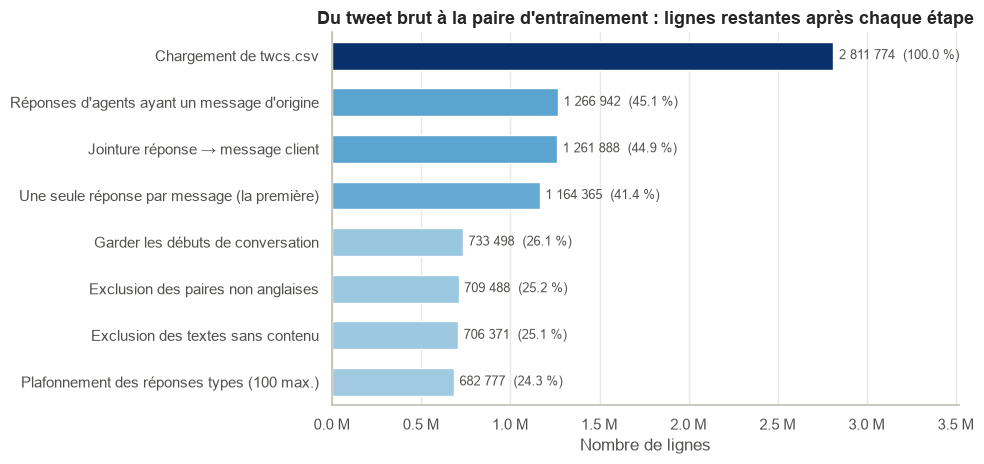

In [30]:
etapes = pd.DataFrame(journal)
total_depart = etapes["lignes en sortie"].iloc[0]   # 2 811 774 tweets bruts

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=etapes, x="lignes en sortie", y="étape", hue="lignes en sortie",
            palette="Blues", hue_norm=bornes_degrade(etapes["lignes en sortie"]),
            legend=False, width=0.6, saturation=1, ax=ax)
for barres in ax.containers:
    ax.bar_label(barres,
                 labels=[f"{espaces(v)}  ({v / total_depart * 100:.1f} %)" for v in barres.datavalues],
                 padding=4, color=GRIS, fontsize=9)
ax.set_title("Du tweet brut à la paire d'entraînement : lignes restantes après chaque étape")
ax.set_xlabel("Nombre de lignes")
ax.set_ylabel("")
ax.set_xlim(0, etapes["lignes en sortie"].max() * 1.25)
ax.xaxis.set_major_formatter(lambda x, _: f"{x/1e6:.1f} M")
ax.grid(axis="y", visible=False)
plt.tight_layout()
sauvegarder(fig, "entonnoir_paires")
plt.show()

**Interprétation :** 

Le journal et le graphique retracent le passage des 2 811 774 tweets bruts
aux **682 777 paires finales**. On part des 1 273 931 réponses d'agents, dont 99 % trouvent leur
message client lors de la jointure. L'étape la plus sélective est la conservation des débuts de
conversation (430 867 paires retirées), qui garantit que chaque message est compréhensible sans
contexte. Les autres filtres (une seule réponse par message, langue, textes sans contenu,
plafonnement des réponses types) retirent chacun moins de 10 % des paires. Chaque exclusion est
justifiée et reproductible.

## 3.8 Statistiques des paires

On décrit le jeu de paires final à l'aide de trois graphiques :

1. **la répartition des paires par marque** (les 10 marques les plus représentées) ;
2. **la distribution de la longueur** des messages et des réponses, en mots ;
3. **la longueur atteinte par 50 %, 90 %, 95 % et 99 % des textes** (percentiles).

La longueur servira à choisir la **longueur maximale** des séquences lors du prétraitement.
Dans les graphiques, le **bleu** représente les messages des clients et l'**orange** les
réponses des agents.

### Répartition des paires par marque

Nombre de paires : 682,777


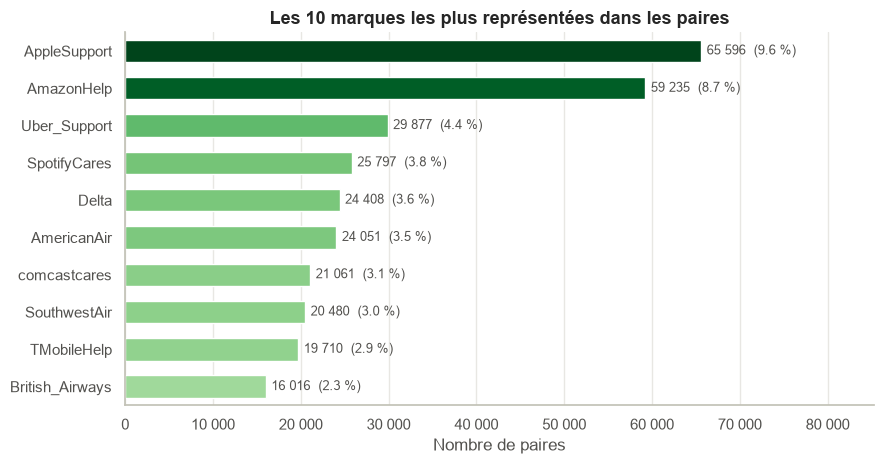

In [31]:
print(f"Nombre de paires : {len(paires):,}")

top = paires["marque"].value_counts().head(10).rename_axis("marque").reset_index(name="paires")

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=top, x="paires", y="marque", hue="paires", palette="Greens",
            hue_norm=bornes_degrade(top["paires"]), legend=False, width=0.6, saturation=1, ax=ax)
for barres in ax.containers:
    ax.bar_label(barres, labels=[f"{espaces(v)}  ({v / len(paires) * 100:.1f} %)" for v in barres.datavalues],
                 padding=4, color=GRIS, fontsize=9)
ax.set_title("Les 10 marques les plus représentées dans les paires")
ax.set_xlabel("Nombre de paires")
ax.set_ylabel("")
ax.set_xlim(0, top["paires"].max() * 1.3)
ax.xaxis.set_major_formatter(espaces)
ax.grid(axis="y", visible=False)
plt.tight_layout()
sauvegarder(fig, "top_marques")
plt.show()

**Interprétation :** 

Les 682 777 paires proviennent de nombreuses marques, sans qu'aucune ne
domine : AppleSupport (65 596 paires, 9,6 %) et AmazonHelp (59 235, 8,7 %) sont les plus
représentées, devant Uber_Support (4,4 %) et SpotifyCares (3,8 %) ; les autres marques du top 10
pèsent chacune entre 2,3 % et 3,6 %. Le top 10 couvre plusieurs secteurs (technologie,
transport aérien, télécommunications, musique) : le modèle apprendra un style de réponse de
service client général, et non celui d'une seule entreprise.

### Répartition des paires par marque

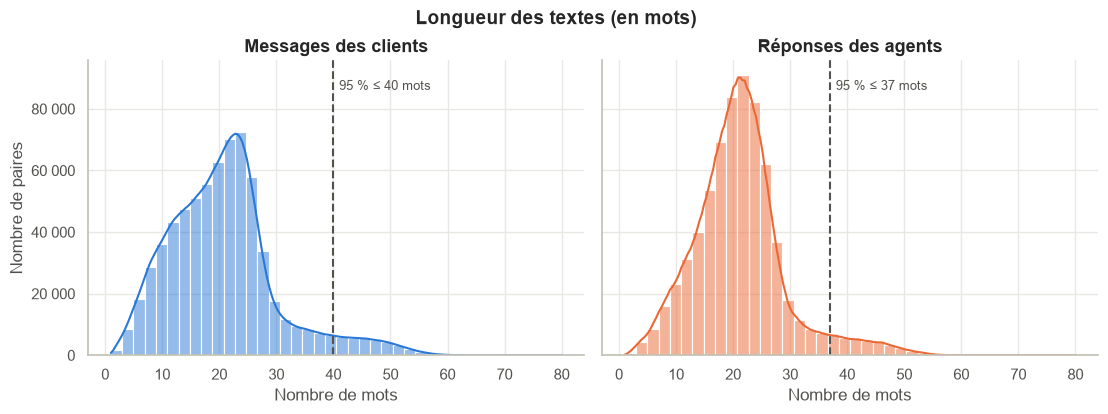

In [32]:
paires["nb_mots_message"] = paires["message"].str.split().str.len()
paires["nb_mots_reponse"] = paires["reponse"].str.split().str.len()

# Un seul tableau "long" : une ligne par texte, avec sa longueur et son type
longueurs = pd.concat([
    pd.DataFrame({"mots": paires["nb_mots_message"], "texte": "Messages des clients"}),
    pd.DataFrame({"mots": paires["nb_mots_reponse"], "texte": "Réponses des agents"}),
])
longueurs["mots"] = longueurs["mots"].clip(upper=80)

g = sns.displot(data=longueurs, x="mots", col="texte", hue="texte", palette=[BLEU, ORANGE],
                binwidth=2, kde=True, legend=False, height=4, aspect=1.4,
                facet_kws={"sharey": True})
for ax, (texte, sous_tableau) in zip(g.axes.flat, longueurs.groupby("texte")):
    p95 = sous_tableau["mots"].quantile(0.95)
    ax.axvline(p95, color=GRIS, linestyle="--", linewidth=1.5)
    ax.text(p95 + 1, ax.get_ylim()[1] * 0.9, f"95 % ≤ {p95:.0f} mots", color=GRIS, fontsize=9)
    ax.set_title(texte)
    ax.set_xlabel("Nombre de mots")
g.axes.flat[0].set_ylabel("Nombre de paires")
g.axes.flat[0].yaxis.set_major_formatter(espaces)
g.figure.suptitle("Longueur des textes (en mots)", fontsize=14, fontweight="bold", y=1.03)
sauvegarder(g.figure, "longueur_paires")
plt.show()

**Interprétation :** 

Les messages des clients et les réponses des agents sont courts : la plupart
comptent entre 10 et 30 mots, avec un pic autour de 20 à 25 mots. La distribution des messages
présente une chute nette vers 25-28 mots, suivie d'une longue queue jusqu'à environ 60 mots :
elle reflète la limite de 140 caractères de Twitter, portée à 280 caractères en novembre 2017,
pendant la période de collecte. Les réponses des agents sont plus homogènes, très concentrées
autour de 20 mots, ce qui traduit un style de réponse plus standardisé. La ligne pointillée
indique que 95 % des messages ont au plus 40 mots, et 95 % des réponses au plus 37 mots.

### Distribution de la longueur des textes

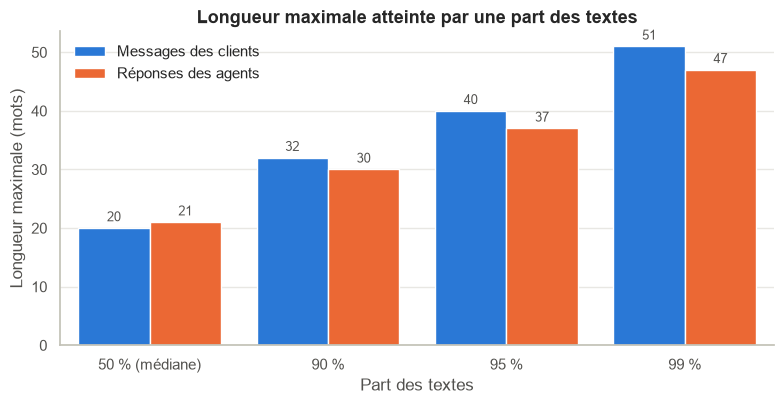

In [33]:
quantiles = {"50 % (médiane)": 0.5, "90 %": 0.9, "95 %": 0.95, "99 %": 0.99}
percentiles = pd.DataFrame([
    {"part": nom, "texte": texte, "mots": paires[colonne].quantile(q)}
    for nom, q in quantiles.items()
    for texte, colonne in [("Messages des clients", "nb_mots_message"),
                           ("Réponses des agents", "nb_mots_reponse")]
])

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=percentiles, x="part", y="mots", hue="texte",
            palette=[BLEU, ORANGE], saturation=1, ax=ax)
for barres in ax.containers:
    ax.bar_label(barres, fmt="%.0f", padding=3, color=GRIS, fontsize=9)
ax.set_xlabel("Part des textes")
ax.set_ylabel("Longueur maximale (mots)")
ax.set_title("Longueur maximale atteinte par une part des textes")
ax.grid(axis="x", visible=False)
ax.legend(title="", frameon=False)
plt.tight_layout()
sauvegarder(fig, "percentiles_longueur")
plt.show()

**Interprétation :** 

La moitié des textes compte au plus 20 mots (messages) ou 21 mots
(réponses). 90 % des textes ont au plus 32 et 30 mots, 95 % au plus 40 et 37 mots, et 99 % au
plus 51 et 47 mots.

**Conséquence pour le prétraitement :** le modèle traite les phrases par paquets, qui doivent
avoir la même longueur : on fixe donc une longueur maximale. Une valeur d'environ **40 mots**
couvre 95 % des textes ; les 5 % de textes plus longs seront coupés. Prendre le maximum
(112 mots) obligerait à compléter toutes les phrases avec des tokens de remplissage, ce qui
ralentirait fortement l'entraînement pour très peu de cas. La valeur définitive sera fixée
après le nettoyage et la tokenisation, car le nombre de tokens diffère du nombre de mots
(la ponctuation devient un token, les mentions et les liens sont supprimés).

## 3.9 Sauvegarde des paires

Les paires sont enregistrées dans `data/processed/paires.csv`. La suite du projet
(prétraitement, modèle, entraînement sur Kaggle) peut ainsi repartir directement de ce fichier,
sans relancer le chargement et le contrôle qualité. On conserve les identifiants des tweets
d'origine, pour pouvoir retrouver la provenance de chaque paire. Les textes sont enregistrés
bruts : le nettoyage est réalisé dans la partie suivante.

In [34]:
colonnes = ["client_id", "reponse_id", "marque", "message", "reponse"]
paires[colonnes].to_csv("../data/processed/paires.csv", index=False)

verification = pd.read_csv("../data/processed/paires.csv")
print(f"Fichier enregistré : {len(verification):,} paires")
print(f"Colonnes           : {list(verification.columns)}")
verification.head(3)

Fichier enregistré : 682,777 paires
Colonnes           : ['client_id', 'reponse_id', 'marque', 'message', 'reponse']


,client_id,reponse_id,marque,message,reponse
0,2291020,2291018,CarlsJr,@665445 Do you know if Carl's Jr serves lunch all day? Or after 1030?,@665443 We serve lunch all day!
1,2651976,2651975,JetBlue,"I really need @VirginAmerica or @JetBlue to have a sale so I can book my airfare to LA. Hint, hi...",@747941 Check our best deals at http://bit.ly/jbdeals\nand sign up for fare alerts: http://bit.l...
2,626918,626916,AmericanAir,@americanair Do you have a number to call you and check the flight status?,"@28752 Text ""FLYAA"" (35922) with your flight number to get instant flight info!"


**Interprétation :** 

Les 682 777 paires finales sont enregistrées dans
`data/processed/paires.csv`, avec les identifiants des tweets d'origine, la marque, le message
du client et la réponse de l'agent. La relecture du fichier confirme que toutes les paires ont
été correctement enregistrées.

### 3.10 Vérification des identifiants

Pour chaque paire du fichier enregistré, on retrouve les tweets d'origine dans le dataset brut
grâce à `client_id` et `reponse_id`, et on vérifie que :
1. le message et la réponse sont bien les textes de ces tweets ;
2. la réponse répond bien à ce message ;
3. le message est écrit par un client, et la réponse par une entreprise ;
4. la marque est bien l'auteur de la réponse.

In [35]:
infos = df.set_index("tweet_id")

controles = {
    "Le message est bien le texte du tweet client_id":
        verification["client_id"].map(infos["text"]) == verification["message"],
    "La réponse est bien le texte du tweet reponse_id":
        verification["reponse_id"].map(infos["text"]) == verification["reponse"],
    "La réponse répond bien à ce message":
        verification["reponse_id"].map(infos["in_response_to_tweet_id"]) == verification["client_id"],
    "Le message est écrit par un client":
        verification["client_id"].map(infos["inbound"]) == True,
    "La réponse est écrite par une entreprise":
        verification["reponse_id"].map(infos["inbound"]) == False,
    "La marque est bien l'auteur de la réponse":
        verification["reponse_id"].map(infos["author_id"]) == verification["marque"],
}

resultats = pd.DataFrame({
    "Contrôle": list(controles.keys()),
    "Paires correctes": [int(c.sum()) for c in controles.values()],
    "% correct": [round(c.mean() * 100, 2) for c in controles.values()],
})
resultats

,Contrôle,Paires correctes,% correct
0,Le message est bien le texte du tweet client_id,682777,100.0
1,La réponse est bien le texte du tweet reponse_id,682777,100.0
2,La réponse répond bien à ce message,682777,100.0
3,Le message est écrit par un client,682777,100.0
4,La réponse est écrite par une entreprise,682777,100.0
5,La marque est bien l'auteur de la réponse,682777,100.0


**Interprétation :** 

Les six contrôles sont satisfaits pour 100 % des 682 777 paires : chaque
paire associe le texte exact du message client et celui de la réponse, la réponse répond bien à
ce message, les rôles (client / entreprise) sont corrects et la marque est bien l'auteur de la
réponse. Ce résultat était attendu, puisque les paires ont été construites à partir de ces
identifiants : le contrôle confirme qu'aucune erreur (colonnes inversées, lignes décalées,
fichier mal enregistré) ne s'est glissée lors de la construction et de la sauvegarde.

# 4. Nettoyage du texte

Les tweets contiennent des éléments inutiles, voire nuisibles, pour l'apprentissage : mentions,
liens, signatures d'agents, emojis, caractères codés en HTML, majuscules. On les nettoie pour que
le modèle apprenne le **contenu** des messages et des réponses, avec un vocabulaire plus petit.

*Différence avec la standardisation de la section 2.2 :* la standardisation servait seulement à
**détecter** les réponses répétées (elle supprimait aussi les nombres et la ponctuation). Le
nettoyage prépare le texte **réellement donné au modèle** : il conserve les nombres, la
ponctuation et la présence d'un lien, qui font partie d'une réponse naturelle.

## 4.1 Charger les paires

On repart du fichier `paires.csv` enregistré à la section 3. Cette section peut donc être
relancée seule, sans refaire le chargement et le contrôle qualité.

In [36]:
import re
import html
import pandas as pd

paires = pd.read_csv("../data/processed/paires.csv", keep_default_na=False)
print(f"Paires chargées : {len(paires):,}")

# Si la section est relancée seule, on recrée le journal de provenance
if "journal" not in globals():
    journal = []
    def enregistrer_etape(etape, operateur, n_entree, n_sortie, justification):
        journal.append({"étape": etape, "opérateur": operateur,
                        "lignes en entrée": n_entree, "lignes en sortie": n_sortie,
                        "lignes retirées": n_entree - n_sortie, "justification": justification})

Paires chargées : 682,777


**Interprétation :** 

Les 682 777 paires enregistrées à la section 3 sont rechargées sans perte.
L'option `keep_default_na=False` garantit que les textes sont lus tels quels (par exemple,
un message « N/A » n'est pas transformé en valeur manquante).

## 4.2 La fonction de nettoyage

Chaque étape est justifiée par l'usage du modèle :

| Étape | Exemple | Pourquoi |
|---|---|---|
| Décoder les caractères HTML | `&amp;` → `&` → `and` | Retrouver le vrai texte |
| Minuscules | `Order` → `order` | Un seul mot au lieu de deux dans le vocabulaire |
| Uniformiser apostrophes et guillemets | `’` → `'` | Éviter deux versions du même mot (`it’s` / `it's`) |
| Remplacer les liens par `<url>` | `https://t.co/x` → `<url>` | Un lien est unique et illisible ; on garde seulement l'information qu'il y avait un lien |
| Supprimer les signatures d'agents | `^JK`, `-AB`, `*JennaLundh` | Ce sont des initiales sans rapport avec la réponse |
| Supprimer les mentions | `@AmazonHelp`, `@115712` | Identifiants propres à chaque tweet |
| Garder le mot des hashtags | `#fail` → `fail` | Le mot porte du sens |
| Supprimer emojis et symboles | `😡`, `$`, `:` | Réduire le vocabulaire |
| Réduire la ponctuation répétée | `!!!` → `!` | Même sens, moins de variantes |
| Séparer la ponctuation | `late!` → `late !` | La ponctuation devient un token à part entière |
| Remplacer les longs numéros par `<num>` | `9613915` → `<num>` | Numéros de commande ou de téléphone uniques : on garde seulement l'information qu'un numéro est donné |

In [37]:
def nettoyer(texte):
    """Prépare un tweet pour l'entraînement du modèle."""
    texte = html.unescape(str(texte))                                # décode les caractères codés (&amp; -> &)
    texte = texte.lower()                                            # tout en minuscules
    texte = (texte.replace("’", "'").replace("‘", "'")               # apostrophes courbes -> droites
                  .replace("“", '"').replace("”", '"'))              # guillemets courbes -> droits
    texte = re.sub(r"https?://\S+|www\.\S+", " xxurl ", texte)       # liens -> marqueur temporaire (devient <url>)
    texte = re.sub(r"[@.]?@\w+", " ", texte)                         # supprime les mentions (AVANT la signature)
    texte = re.sub(r"(?:\s[-–—]|\s*[\^\*~])\s?[a-z]{1,20}\s*$", " ", texte)  # supprime la signature de l'agent à la fin
    texte = re.sub(r"\d{5,}", " xxnum ", texte)                      # numéros de 5 chiffres ou plus -> marqueur (devient <num>)
    texte = texte.replace("&", " and ").replace("#", " ")            # & -> and ; #fail -> fail
    texte = re.sub(r"[^a-z0-9'.,!?\s]", " ", texte)                  # supprime emojis et symboles (garde lettres, chiffres, . , ! ? ')
    texte = re.sub(r"(?<![a-z])'|'(?![a-z])", " ", texte)            # supprime les apostrophes hors des mots (garde don't, it's)
    texte = re.sub(r"([.,!?])\1+", r"\1", texte)                     # ponctuation répétée -> une seule (!!! -> !)
    texte = re.sub(r"(?<!\d)\.|\.(?!\d)", " . ", texte)              # point séparé, sauf entre deux chiffres (1.5, 11.0.2)
    texte = re.sub(r"([,!?])", r" \1 ", texte)                       # sépare , ! ? des mots
    texte = re.sub(r"\s+", " ", texte).strip()                       # un seul espace entre les mots
    texte = re.sub(r"^(?:[.,!?]\s*)+", "", texte)                    # supprime la ponctuation au début du texte
    return texte.replace("xxurl", "<url>").replace("xxnum", "<num>")

pd.set_option("display.max_colwidth", 120)
exemples = paires.sample(5, random_state=1)
pd.DataFrame({
    "message avant": exemples["message"], "message après": exemples["message"].map(nettoyer),
    "réponse avant": exemples["reponse"], "réponse après": exemples["reponse"].map(nettoyer),
})

,message avant,message après,réponse avant,réponse après
351099,@AppleSupport fix this https://t.co/O8jF4ksKsC,fix this <url>,@485659 We want to help. Have you tried the steps here? https://t.co/xU1AGHStV6,we want to help . have you tried the steps here ? <url>
53130,@airtel_care how do I add family and friends numbers on my Airtel line...,how do i add family and friends numbers on my airtel line .,"@206179 Hello @206179, please be informed that FAF codes are dependent on your tariff plan. Kindly provide your mobi...","hello , please be informed that faf codes are dependent on your tariff plan . kindly provide your mobile number via ..."
453997,@Delta Help!! My niece just left our iPad on flight 3456 into LGA! We were sitting in row 4.,help ! my niece just left our ipad on flight 3456 into lga ! we were sitting in row 4 .,"@533455 Elizabeth, we will make every effort to locate the iPadasap. To assist us, please complete our Lost Item Rep...","elizabeth , we will make every effort to locate the ipadasap . to assist us , please complete our lost item report h..."
308942,"@AmazonHelp order no. 408-9613915-0161138\nJust one question, what is my fault in all this and you are telling me po...","order no . 408 <num> <num> just one question , what is my fault in all this and you are telling me policies",@123355 Please don’t provide your order details as we consider them to be personal info. Our page is visible to publ...,please don't provide your order details as we consider them to be personal info . our page is visible to public . sg...
253027,Why isn’t the new season of @180004 on @115940 😞,why isn't the new season of on,"@425429 Thanks for reaching out, Haley! We expect to receive S4 sometime after it finishes airing. Keep an eye on y...","thanks for reaching out , haley ! we expect to receive s4 sometime after it finishes airing . keep an eye on your wl..."


**Interprétation :** 

Le nettoyage supprime les mentions (y compris au milieu d'un message,
comme « hello @206179 »), les signatures et les emojis, remplace les liens par `<url>` et les
longs numéros (commande, téléphone) par `<num>`, met le texte en minuscules et sépare la
ponctuation. Les petits nombres utiles sont conservés (« flight 3456 », « row 4 ») et le sens
des messages et des réponses est préservé.

Les signatures d'agents prennent plusieurs formes (`^LK`, `-AB`, `–DMG`, `*JennaLundh`),
parfois collées à la ponctuation ou suivies d'une mention : la règle de suppression a été
adaptée après examen du texte brut de ces cas.

Deux limites apparaissent : les mentions placées au milieu d'une phrase désignaient parfois un
nom anonymisé dans le dataset, dont la suppression rend la phrase incomplète (« why isn't the
new season of on ») ; et les réponses d'agents contiennent souvent le prénom du client
(« elizabeth », « haley »), que le modèle ne pourra pas reproduire correctement. Ces cas
restent minoritaires.

## 4.3 Nettoyer toutes les paires

On applique le nettoyage aux messages et aux réponses. Les paires dont un texte devient vide
(par exemple, un message qui ne contenait que des emojis) sont retirées.

In [38]:
paires["message_propre"] = paires["message"].map(nettoyer)
paires["reponse_propre"] = paires["reponse"].map(nettoyer)

n_avant = len(paires)
paires = paires[(paires["message_propre"] != "") &
                (paires["reponse_propre"] != "")].reset_index(drop=True)
journal = [e for e in journal if e["étape"] != "Nettoyage du texte (textes vides retirés)"]
enregistrer_etape("Nettoyage du texte (textes vides retirés)", "transformation", n_avant, len(paires),
                  "Message ou réponse vide après nettoyage (emojis, symboles uniquement)")

print(f"Paires vides après nettoyage : {n_avant - len(paires):,} | paires restantes : {len(paires):,}")

Paires vides après nettoyage : 816 | paires restantes : 681,961


**Interprétation :** 

Le nettoyage rend vides 816 paires (≈ 0,12 %), retirées du jeu de données ;
il reste **681 961 paires**. Il s'agit surtout de messages ou de réponses composés uniquement
d'emojis, de symboles, de ponctuation ou d'une signature d'agent : ils n'étaient pas vides après
la standardisation de la section 3, qui conservait ces caractères, mais le deviennent après le
nettoyage, qui les supprime.

## 4.4 Longueur en tokens et choix de la longueur maximale

Après le nettoyage, chaque mot et chaque signe de ponctuation est un **token**. On mesure la
longueur des textes en tokens et on fixe la longueur maximale au **95ᵉ percentile**, séparément
pour les messages et pour les réponses : 95 % des textes seront conservés en entier.

In [39]:
paires["nb_tokens_message"] = paires["message_propre"].str.split().str.len()
paires["nb_tokens_reponse"] = paires["reponse_propre"].str.split().str.len()

print("=== Longueur en tokens ===")
print(paires[["nb_tokens_message", "nb_tokens_reponse"]]
      .describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

MAX_LEN_MESSAGE = int(paires["nb_tokens_message"].quantile(0.95))
MAX_LEN_REPONSE = int(paires["nb_tokens_reponse"].quantile(0.95))

print(f"\nLongueur maximale des messages : {MAX_LEN_MESSAGE} tokens "
      f"({(paires['nb_tokens_message'] > MAX_LEN_MESSAGE).mean():.1%} des messages seront tronqués)")
print(f"Longueur maximale des réponses : {MAX_LEN_REPONSE} tokens "
      f"({(paires['nb_tokens_reponse'] > MAX_LEN_REPONSE).mean():.1%} des réponses seront tronquées)")

=== Longueur en tokens ===
       nb_tokens_message  nb_tokens_reponse
count           681961.0           681961.0
mean                21.3               22.3
std                 10.5                8.8
min                  1.0                1.0
50%                 21.0               22.0
90%                 34.0               32.0
95%                 43.0               39.0
99%                 54.0               51.0
max                164.0               76.0

Longueur maximale des messages : 43 tokens (4.7% des messages seront tronqués)
Longueur maximale des réponses : 39 tokens (4.9% des réponses seront tronquées)


**Interprétation :** 

Après nettoyage, les messages comptent en moyenne 21,3 tokens et les
réponses 22,3 tokens : les séquences sont courtes, ce qui convient bien à un modèle LSTM.
Les longueurs sont légèrement supérieures à celles mesurées en mots, car la ponctuation est
désormais comptée comme des tokens séparés. On fixe la longueur maximale au 95ᵉ percentile :
**43 tokens pour les messages** et **39 tokens pour les réponses**. Seuls 4,7 % des messages et
4,9 % des réponses seront tronqués ; les textes plus longs (jusqu'à 164 tokens) restent
exceptionnels (99 % des messages ont au plus 54 tokens).

## 4.5 Sauvegarde des paires nettoyées

Les paires nettoyées sont enregistrées dans `data/processed/paires_nettoyees.csv`. C'est ce
fichier qui servira à l'entraînement du modèle, en local comme sur Kaggle.

In [40]:
colonnes = {"client_id": "client_id", "reponse_id": "reponse_id", "marque": "marque",
            "message_propre": "message", "reponse_propre": "reponse"}
paires[list(colonnes)].rename(columns=colonnes).to_csv(
    "../data/processed/paires_nettoyees.csv", index=False)

verification = pd.read_csv("../data/processed/paires_nettoyees.csv", keep_default_na=False)
print(f"Fichier enregistré : {len(verification):,} paires nettoyées")
verification.head(20)

Fichier enregistré : 681,961 paires nettoyées


,client_id,reponse_id,marque,message,reponse
0,2291020,2291018,CarlsJr,do you know if carl's jr serves lunch all day ? or after 1030 ?,we serve lunch all day !
1,2651976,2651975,JetBlue,"i really need or to have a sale so i can book my airfare to la . hint , hint",check our best deals at <url> and sign up for fare alerts <url>
2,626918,626916,AmericanAir,do you have a number to call you and check the flight status ?,text flyaa <num> with your flight number to get instant flight info !
3,1278330,1278329,sprintcare,i can not make any calls whats the problem sprint 4g please let me out of my contact,what's your zip code ?
4,2450852,2450851,VirginTrains,"booking virgin train tickets nightmare , wont let me empty the basket and start again . have to wait 2 hrs for baske...",there is a remove button at the bottom of the journey . click that and your basket will empty .
5,1821511,1821510,NikeSupport,if i know my old username for nike how can i find which email account it's linked up to ?,if you provide us with your nike screen name case sensitive we can supply you with the email that s linked to your a...
6,810188,810186,AskCiti,what is the cost for notary public services for citi members ?,"thank you for the inquiry . there would be a fee of 10.00 for each signature , depending on the type of notary reque..."
7,372834,372831,ChipotleTweets,"i just moved from cleveland , oh to newnan , ga and there's no chipotle here . do you think we can do something abou...","hmm , no plans for newnan yet , but i hope we get there someday !"
8,2855752,2855751,SW_Help,i didn't think you could drink alcohol on man on carriage just cracked open a can !,the alcohol ban doesn't apply to national rail services . only transport for london .
9,1006269,1006268,VirginTrains,still stuck with 90p a bag of plain crisps for meals . come on vt stop excluding vegans ! we can't always carry lunc...,"hi littlebluehensoap , what vegan produce do you think we need the most ? and is this in first class or the shop ?"


**Interprétation :** 

Les 681 961 paires nettoyées sont enregistrées dans
`data/processed/paires_nettoyees.csv`. Les textes sont en minuscules, sans mentions, signatures
ni emojis, avec la ponctuation séparée et les liens et longs numéros remplacés par `<url>` et
`<num>`. Ce fichier est le point de départ de l'entraînement du modèle.